# Gráficos extras (Pergunta 2)

Aqui ficam dois gráficos que complementam a Pergunta 2: o gráfico lollipop das causas mais frequentes e o mapa do Brasil com o total de mortos por estado. A ideia deles veio do colega Lucas; o código foi refeito para usar os dados limpos do projeto.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon
import plotly.express as px

dados = pd.read_csv("../data/processed/acidentes_prf_2020_2025.csv")
dados.shape

(406255, 10)

## 1. Lollipop: causas mais frequentes

Aqui contamos **acidentes** (todos, com ou sem morte) por causa. Isso é diferente do gráfico de barras da Pergunta 2, que somou **mortos**.

In [2]:
frequencia = dados["causa_acidente"].value_counts().head(15).sort_values()
frequencia.tail(5)

causa_acidente
Condutor deixou de manter distância do veículo da frente     22623
Velocidade Incompatível                                      30308
Acessar a via sem observar a presença dos outros veículos    31189
Ausência de reação do condutor                               44664
Reação tardia ou ineficiente do condutor                     46952
Name: count, dtype: int64

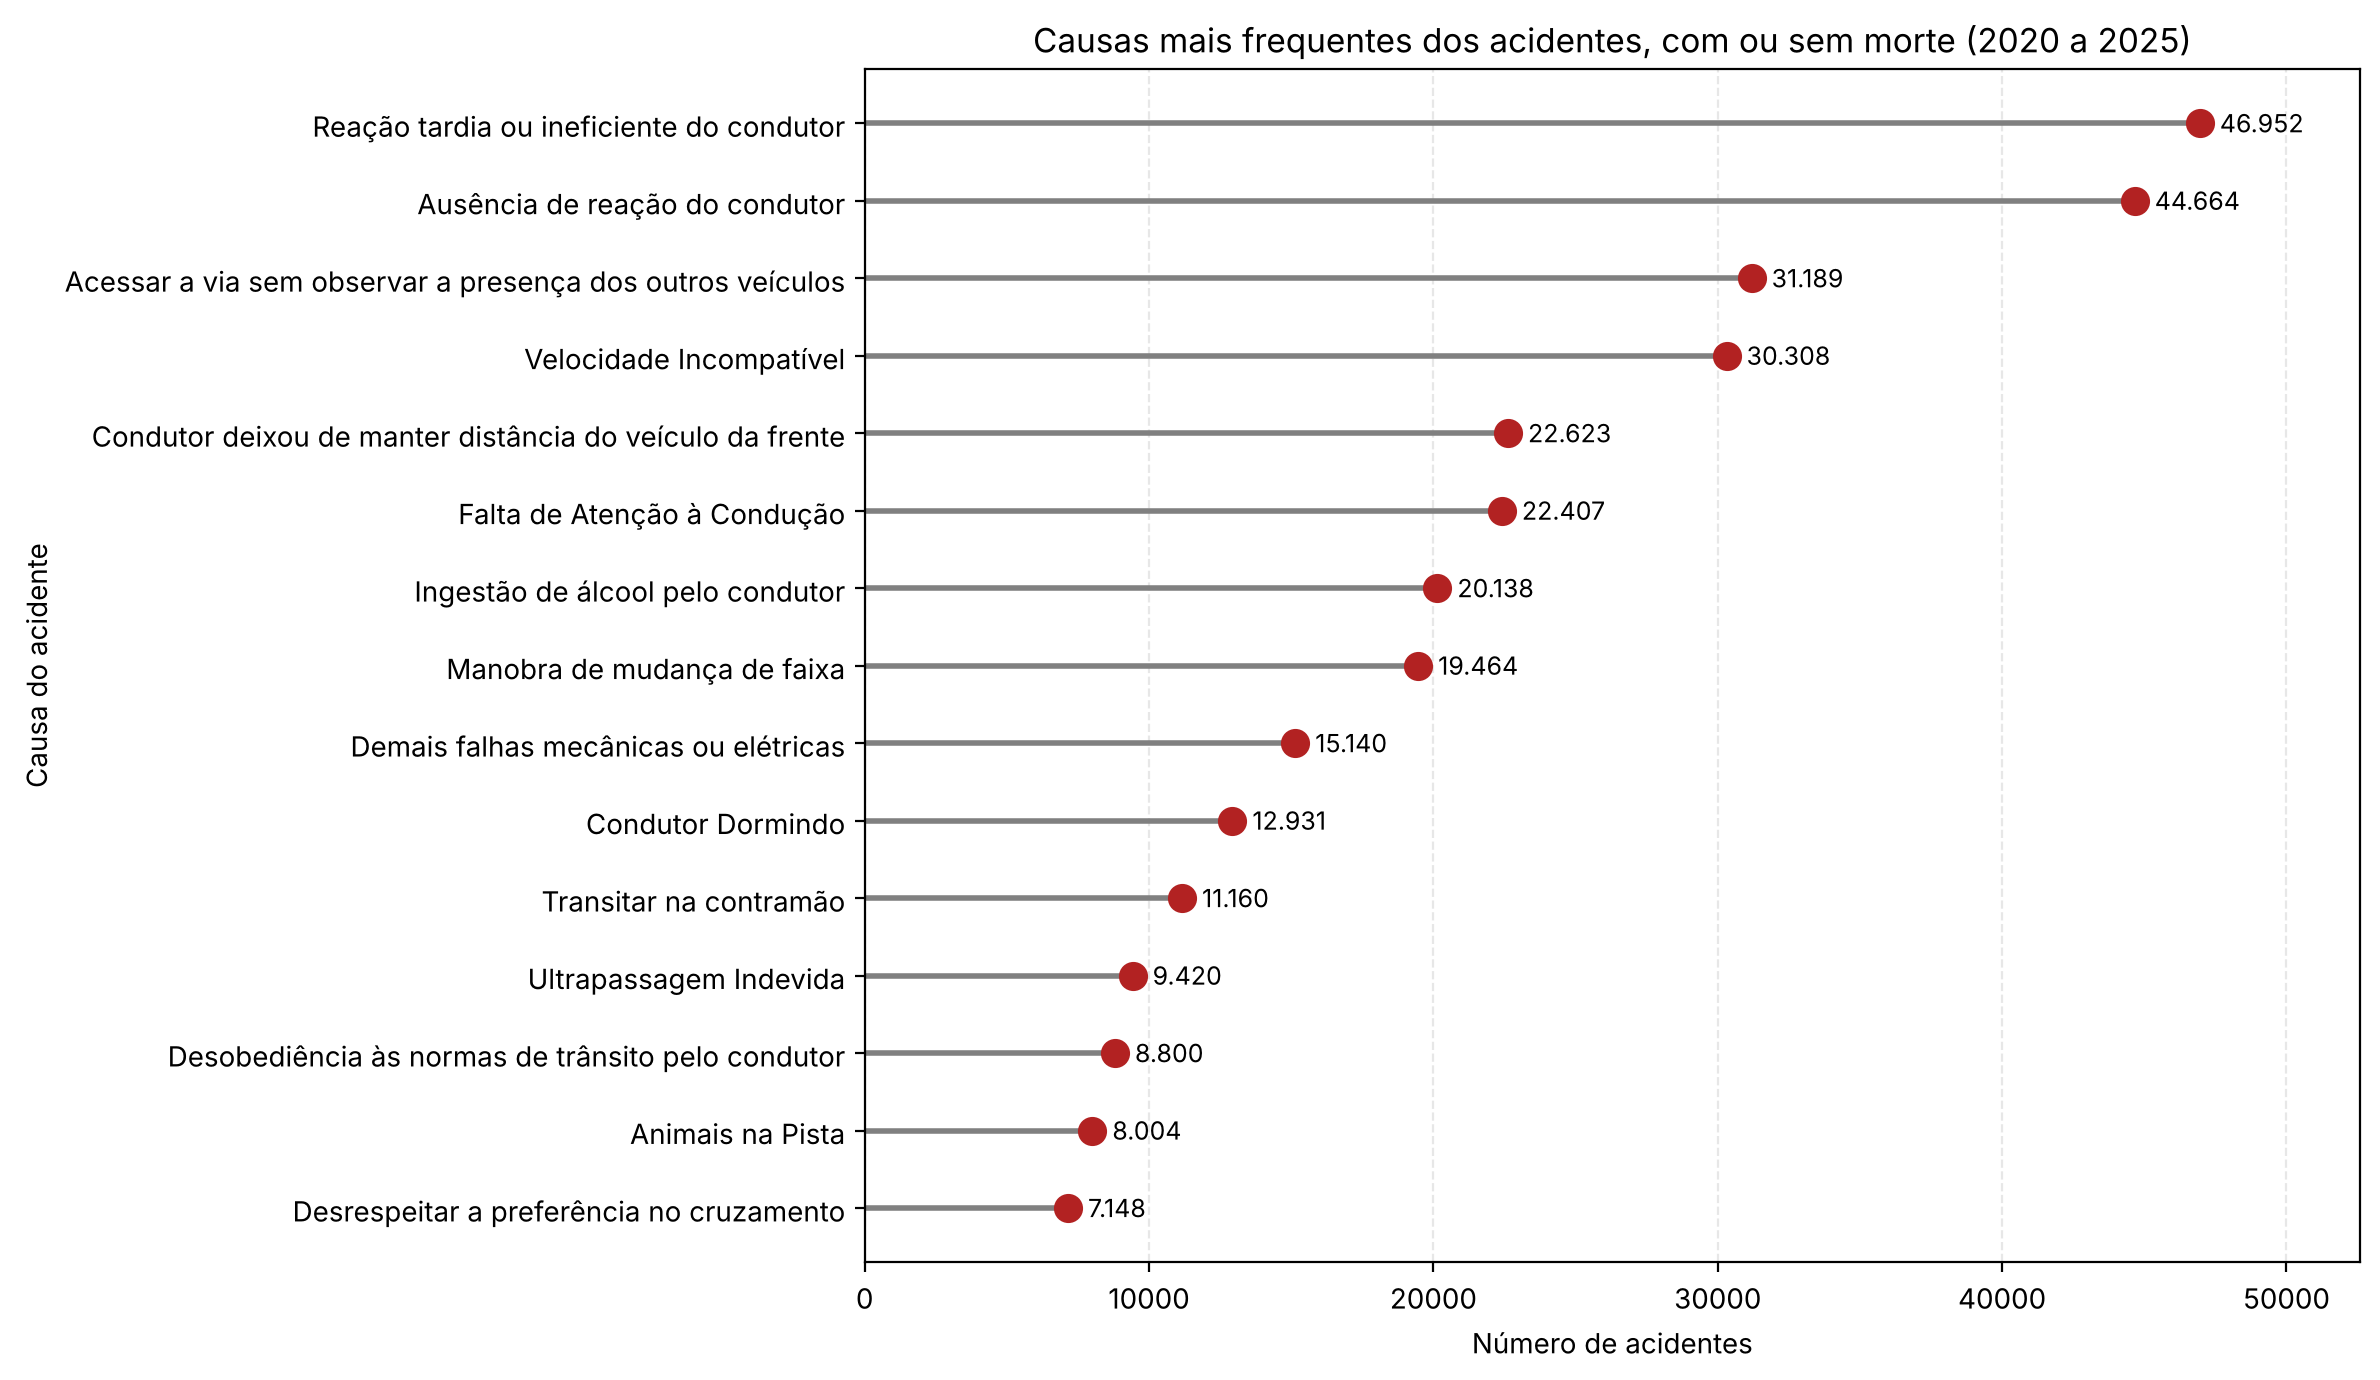

In [3]:
plt.figure(figsize=(12, 7))
plt.hlines(y=frequencia.index, xmin=0, xmax=frequencia.values, color="gray", linewidth=2)
plt.scatter(frequencia.values, frequencia.index, color="firebrick", s=90, zorder=3)

folga = frequencia.max() * 0.015
for i, valor in enumerate(frequencia.values):
    plt.text(valor + folga, i, f"{valor:,}".replace(",", "."), va="center", fontsize=9)

plt.title("Causas mais frequentes dos acidentes, com ou sem morte (2020 a 2025)")
plt.xlabel("Número de acidentes")
plt.ylabel("Causa do acidente")
plt.xlim(0, frequencia.max() * 1.12)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig("../dashboard/p3_lollipop_causas_frequencia.png", dpi=150, bbox_inches="tight")
plt.show()

### Frequência × mortes

Vamos comparar a posição de cada causa quando contamos acidentes e quando contamos mortos.

In [4]:
acidentes_causa = dados.groupby("causa_acidente").size()
mortos_causa = dados.groupby("causa_acidente")["mortos"].sum()

comparacao = pd.DataFrame({"acidentes": acidentes_causa, "mortos": mortos_causa})
comparacao["posicao_acidentes"] = comparacao["acidentes"].rank(ascending=False).astype(int)
comparacao["posicao_mortos"] = comparacao["mortos"].rank(ascending=False).astype(int)
comparacao.sort_values("mortos", ascending=False).head(8)

,acidentes,mortos,posicao_acidentes,posicao_mortos
causa_acidente,,,,
Transitar na contramão,11160,4168,11,1
Velocidade Incompatível,30308,3280,4,2
Ausência de reação do condutor,44664,3262,2,3
Reação tardia ou ineficiente do condutor,46952,2850,1,4
Ultrapassagem Indevida,9420,2209,12,5
Acessar a via sem observar a presença dos outros veículos,31189,1872,3,6
Pedestre andava na pista,3267,1397,26,7
Condutor Dormindo,12931,1274,10,8


## 2. Mapa do Brasil: mortos por estado

Somamos a coluna `mortos` de cada estado. A malha dos estados está em `data/external/brasil_estados.geojson`.

In [5]:
mortes_uf = dados.groupby("uf")["mortos"].sum().reset_index()
mortes_uf.sort_values("mortos", ascending=False).head(5)

,uf,mortos
10,MG,4396
17,PR,3427
4,BA,3302
23,SC,2303
15,PE,1858


In [6]:
with open("../data/external/brasil_estados.geojson", encoding="utf-8") as f:
    estados = json.load(f)

fig = px.choropleth(
    mortes_uf,
    geojson=estados,
    locations="uf",
    featureidkey="properties.uf",
    color="mortos",
    color_continuous_scale="Reds",
    labels={"mortos": "Mortos"},
    title="Mortos em acidentes nas rodovias federais por estado (2020 a 2025)",
)
fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(title_x=0.5, height=700, width=900)
fig.write_html("../dashboard/p3_mapa_mortos_estado.html")
fig

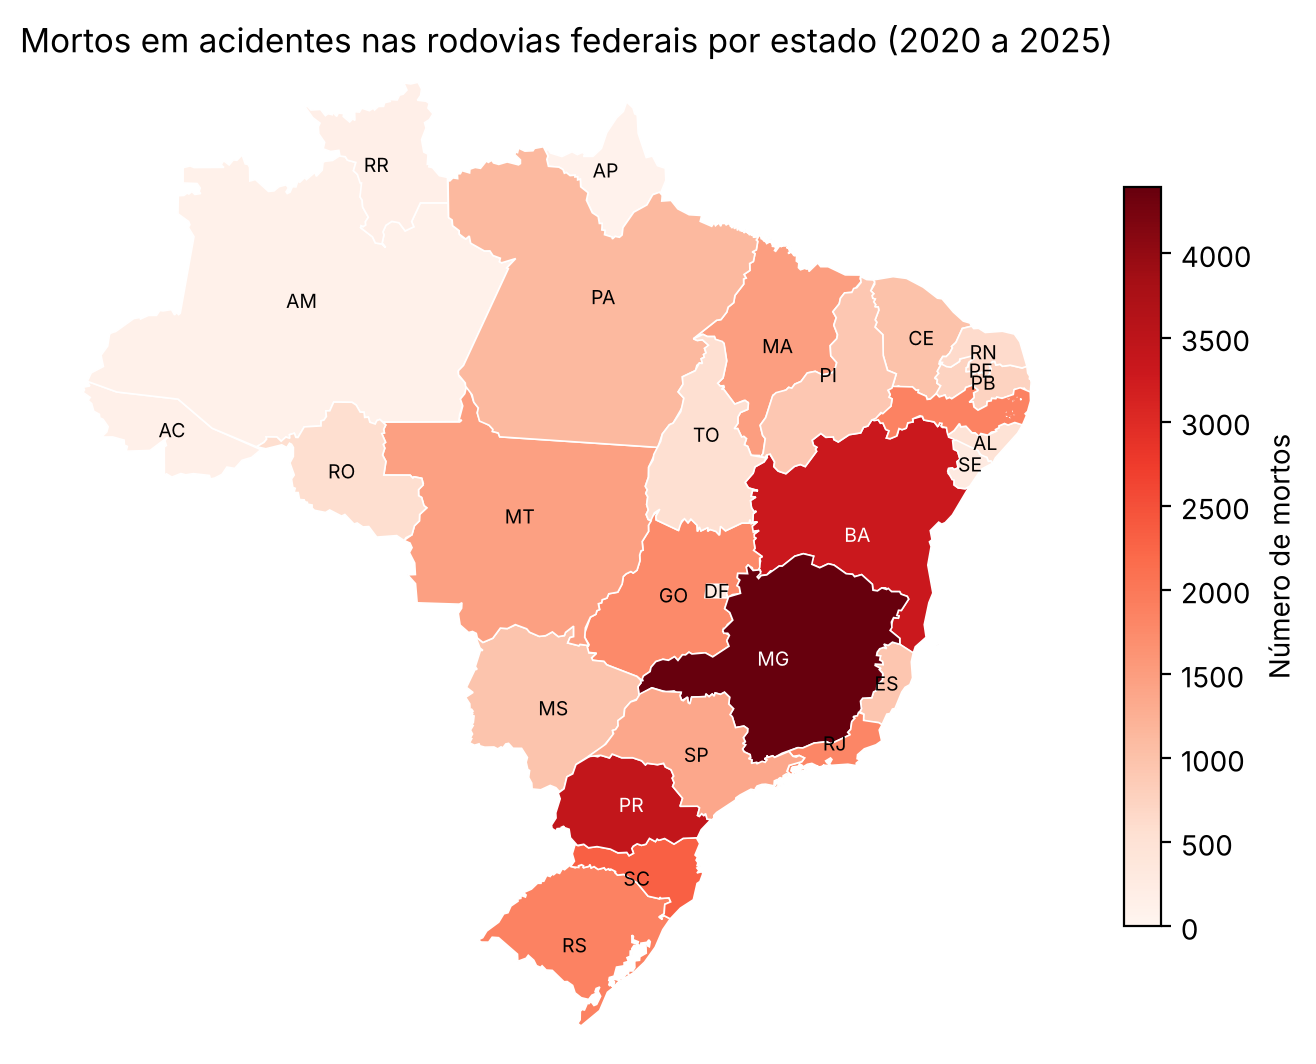

In [7]:
valores = mortes_uf.set_index("uf")["mortos"]
cmap = plt.get_cmap("Reds")
norma = plt.Normalize(0, valores.max())

fig2, ax = plt.subplots(figsize=(8, 8))
for feicao in estados["features"]:
    uf = feicao["properties"]["uf"]
    geom = feicao["geometry"]
    partes = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    for parte in partes:
        ax.add_patch(Polygon(parte[0], closed=True, facecolor=cmap(norma(valores[uf])), edgecolor="white", linewidth=0.6))
    # sigla no centro aproximado do estado
    todos = [p for parte in partes for p in parte[0]]
    xs = [p[0] for p in todos]; ys = [p[1] for p in todos]
    cor_texto = "white" if valores[uf] > valores.max() * 0.6 else "black"
    ax.text((min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2, uf, ha="center", va="center", fontsize=7, color=cor_texto)

ax.set_xlim(-74.5, -33.5)
ax.set_ylim(-34.5, 5.8)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Mortos em acidentes nas rodovias federais por estado (2020 a 2025)")
barra = plt.cm.ScalarMappable(norm=norma, cmap=cmap)
fig2.colorbar(barra, ax=ax, shrink=0.6, label="Número de mortos")
plt.savefig("../dashboard/p3_mapa_mortos_estado.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusões dos gráficos extras

- No lollipop, as causas com mais acidentes (com ou sem morte) foram reação tardia ou ineficiente do condutor (46.952), ausência de reação do condutor (44.664) e acessar a via sem observar os outros veículos (31.189).
- A ordem muda quando contamos mortos: "Transitar na contramão" é a 11ª em número de acidentes (11.160), mas a 1ª em número de mortos (4.168). "Ultrapassagem indevida" e "Pedestre andava na pista" também sobem muito.
- Ou seja, as causas mais frequentes não são as que mais aparecem nas mortes. Esta comparação mostra o que foi registrado, e não prova que uma causa seja mais "perigosa" que a outra.
- No mapa, os estados com mais mortos foram MG (4.396), PR (3.427) e BA (3.302). Estados com mais rodovias e mais tráfego tendem a ter mais mortos, então o mapa mostra quantidade e não o risco de cada estado.
